# Brain Tumor Detection Dataset

This project uses the public **MRI for Brain Tumor with Bounding Boxes** dataset to study object detection on brain MRI images. The images include axial, sagittal, and coronal views. Annotations are stored as YOLO text files containing a class ID and normalized bounding-box coordinates.

The dataset description reports **5,249 images**, approximately **140.24 MB** in the downloadable archive, and an original split into training and validation sets. The four original classes are Glioma (0), Meningioma (1), No Tumor (2), and Pituitary (3).

| Original class | Training images | Validation images | Total |
|---|---:|---:|---:|
| Glioma | 1,153 | 136 | 1,289 |
| Meningioma | 1,449 | 140 | 1,589 |
| No Tumor | 711 | 100 | 811 |
| Pituitary | 1,424 | 136 | 1,560 |
| **Total** | **4,737** | **512** | **5,249** |

The original dataset has no separate test split. The No Tumor category is an image-level category whose existing boxes cover parts of the brain, as illustrated in the annotation review below. The dataset page lists the license as CC0: Public Domain.

Source: [MRI for Brain Tumor with Bounding Boxes on Kaggle](https://www.kaggle.com/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes)


In [1]:
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import argparse
import random
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import matplotlib

# Working with Data

## Annotation review

Each YOLO label row contains a class ID and normalized box coordinates: class_id x_center y_center width height. The following figures summarize the visual inspection.


### Training examples

Random examples from the training set show bounding boxes for the four original classes.

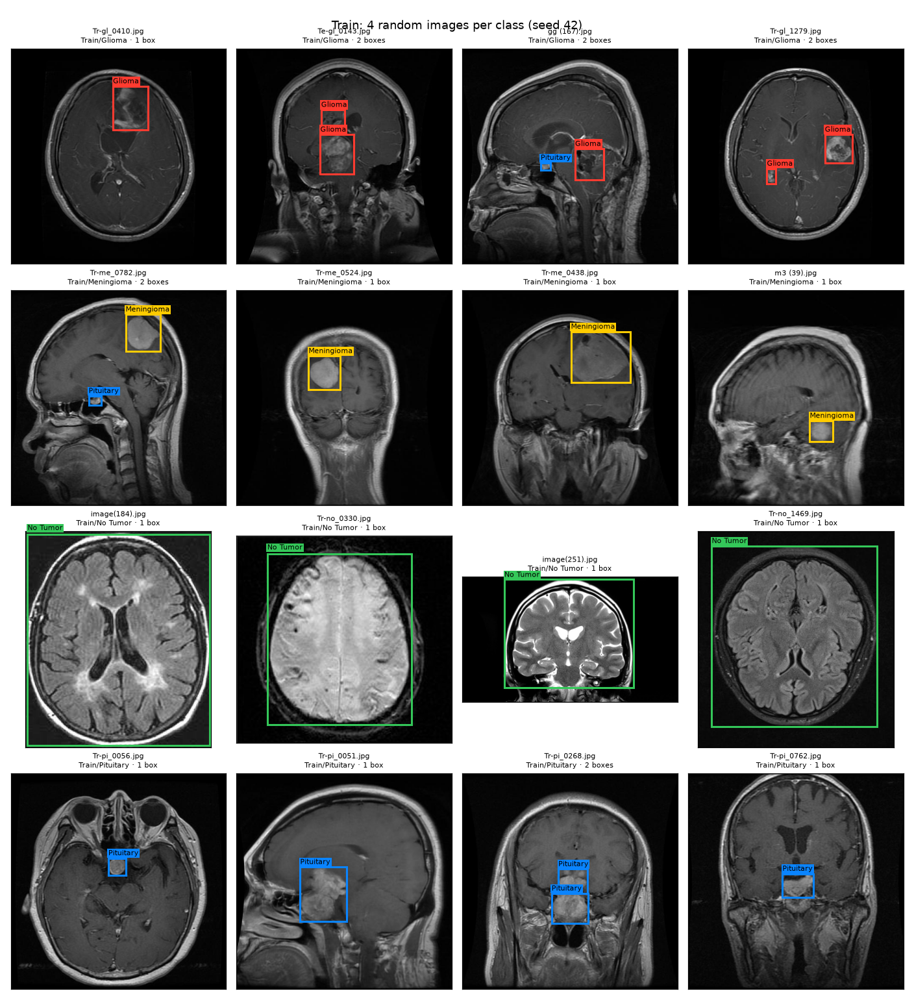


### Validation examples

Random examples from the validation set show the same annotation format.

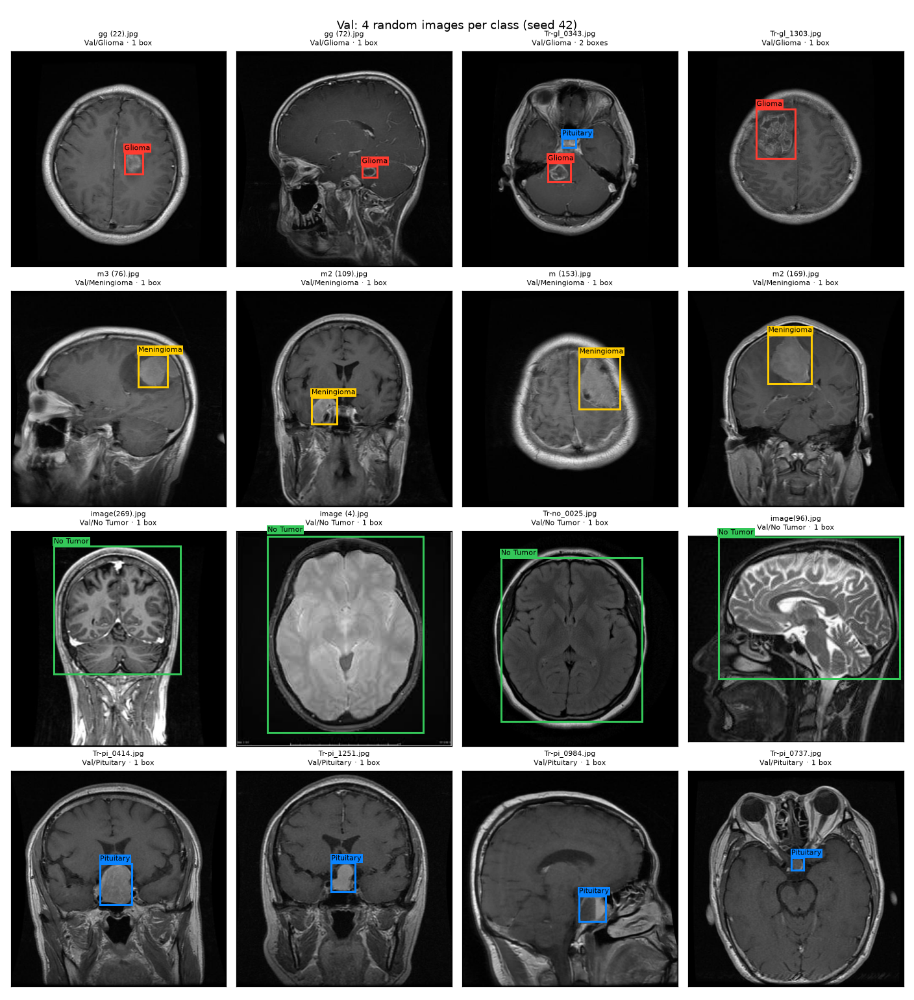


### No Tumor boxes

In these examples, class 2 boxes cover much of the brain. For tumor detection, these images can be retained as negative examples with empty labels after removing the No Tumor boxes.

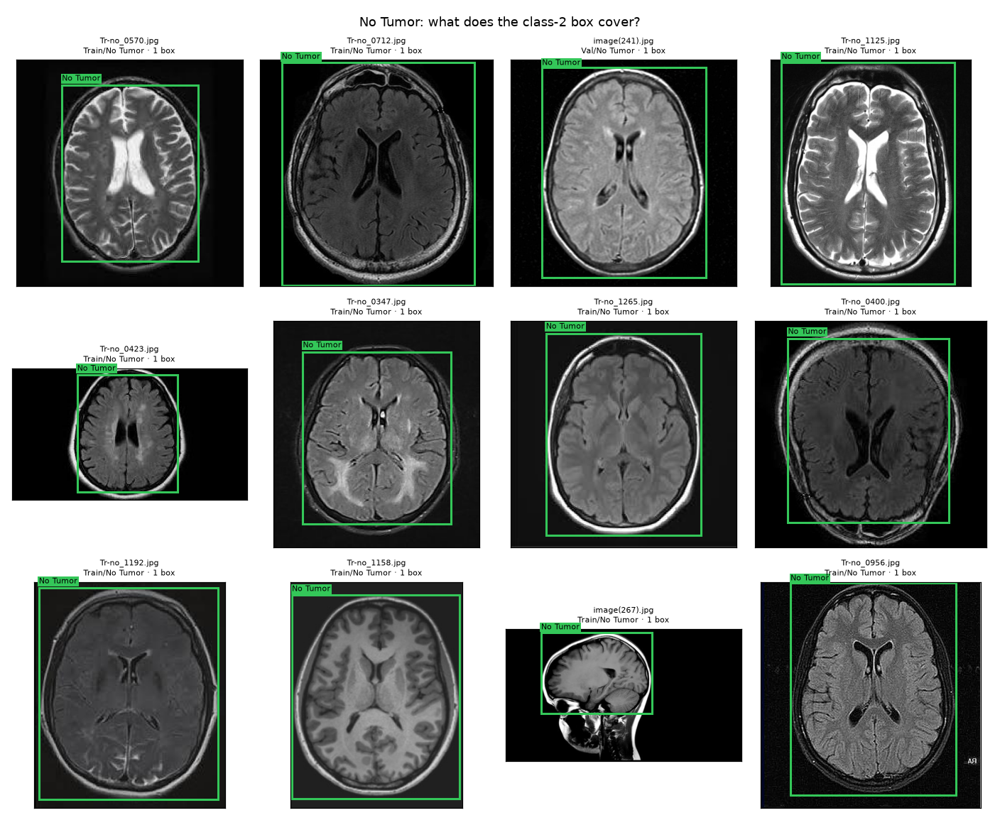


### Multiple classes in one label

The audit reports 257 label files with more than one class. Additional Pituitary boxes in Glioma and Meningioma images need review. The images alone do not establish whether these annotations are correct.

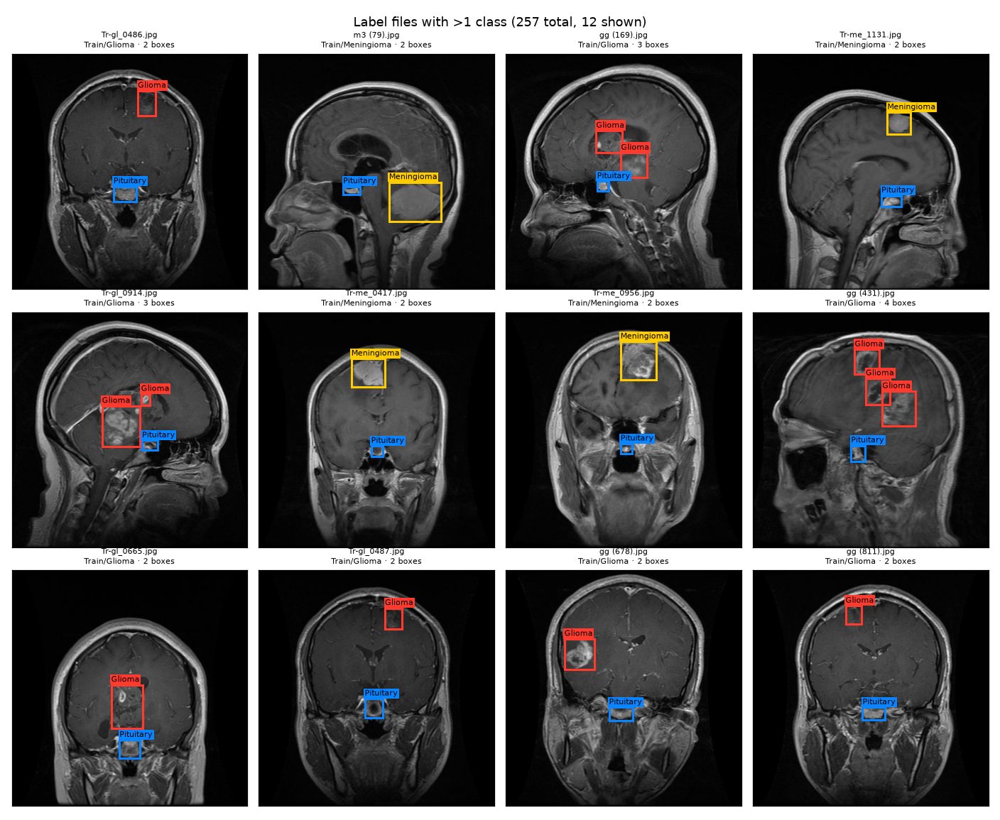


### Folder and label class mismatches

Some box classes differ from the containing folder. A mismatch warrants review and does not establish which label is correct. Similar-looking images, such as m (49) through m (55), should be grouped when splitting the data.

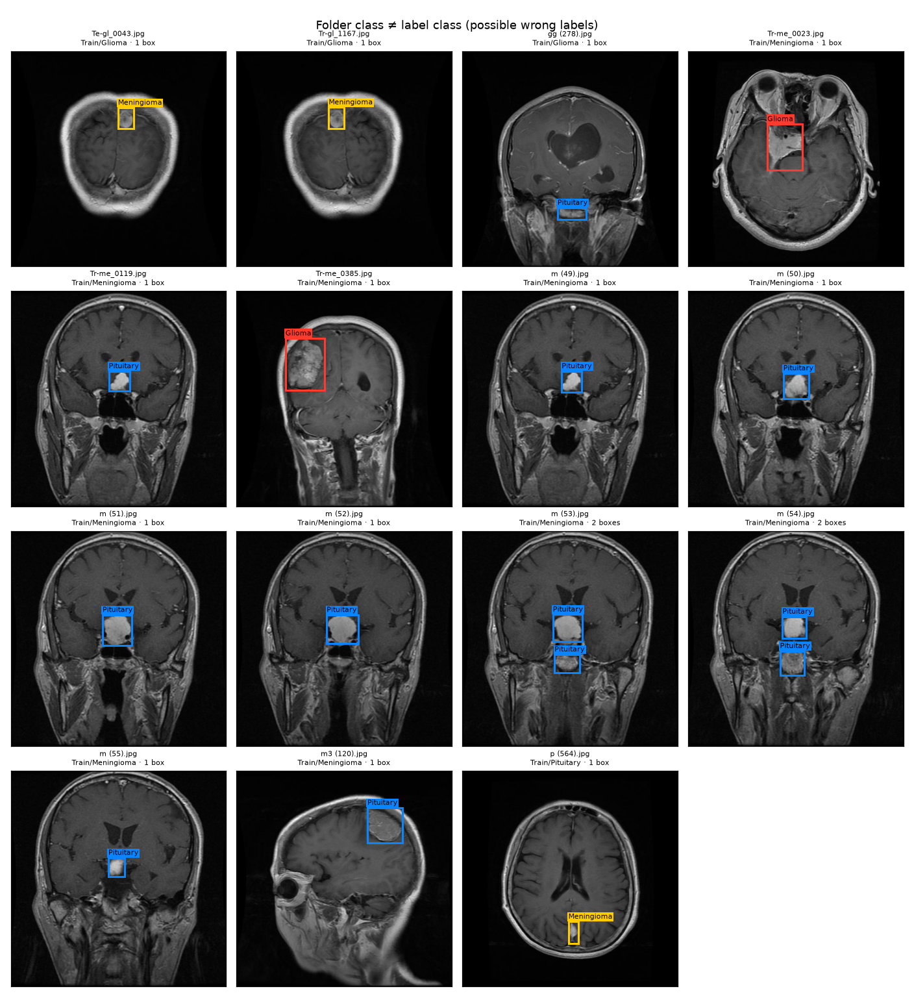


### Empty or missing labels

The label for Val/Glioma/gg (342).jpg is empty and should be reviewed before use. The two displayed No Tumor images have no matching label files and can be treated as negative examples if their source category is trusted.

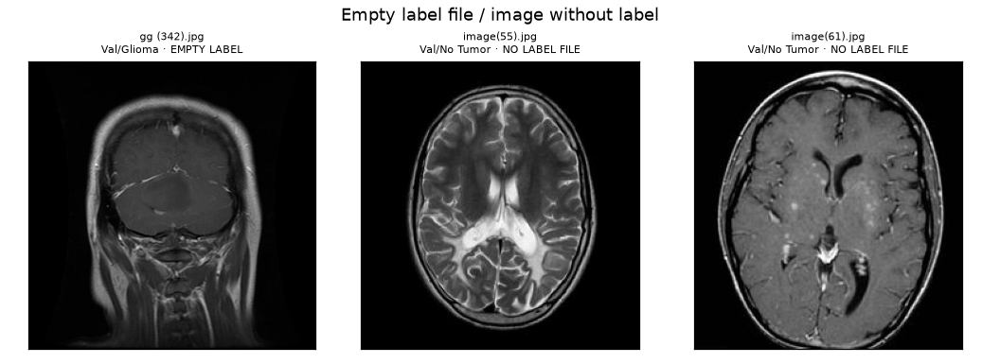


### Checking image-to-label matching

These examples intentionally pair image(55).jpg and image(61).jpg with label files from other images. They illustrate why labels must be matched by filename and should not be treated as confirmed annotations for these images.

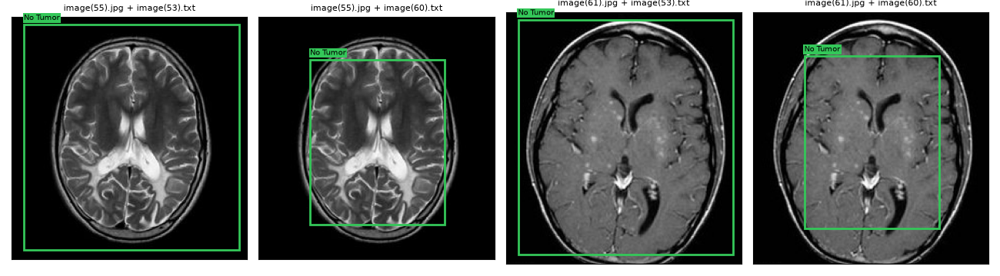


### Next steps for data cleaning

1. Check image-label matches, box coordinates, empty labels, and ambiguous annotations.
2. Prepare a separate copy, remove No Tumor boxes, and retain trusted negative images with empty labels.
3. Review or exclude uncertain annotations and document the decisions. For three tumor classes, map the original Pituitary class from 3 to 2, keeping Glioma as 0 and Meningioma as 1.
4. Create train, validation, and test splits while grouping duplicates, similar images, and images from the same patient when patient identifiers are available. Record the method, seed, and counts.
5. Inspect the cleaned annotations visually before training.

These observations are based on the displayed samples and do not confirm the accuracy of all labels or diagnoses.


## Step 1. Annotation audit

The audit reads the original `data/archive` and does not modify it. Each image is checked for:

- **Image–label match:** a label file with the same filename stem exists in the neighbouring `labels` folder. Label files without an image are listed separately.
- **Box coordinates:** every row has 5 values, a known class ID, `0 < w, h ≤ 1`, and box edges inside `[0, 1]` (tolerance `1e-3` for rounding). Repeated identical rows are flagged.
- **Empty labels:** a label file that contains no boxes.
- **Readable image:** the file opens with PIL.
- **Ambiguous annotations** (flagged for review, not changed): more than one class in one file; no box of the folder's class; exact duplicate images (same MD5) whose copies have different classes or boxes that overlap with IoU < 0.5; duplicates present in both Train and Val.

The full table is saved to `reports/annotation_audit.csv`.

In [2]:
import hashlib
import shutil
from itertools import combinations

import pandas as pd

RAW_ROOT = Path("data/archive")
REPORT_DIR = Path("reports")
SPLITS = ["Train", "Val"]
CLASS_NAMES = {0: "Glioma", 1: "Meningioma", 2: "No Tumor", 3: "Pituitary"}
FOLDER_TO_ID = {name: class_id for class_id, name in CLASS_NAMES.items()}
NO_TUMOR_ID = 2
IMAGE_EXTS = {".jpg", ".jpeg", ".png"}
COORD_TOL = 1e-3   # allowed rounding error for normalized coordinates
DUP_IOU_MIN = 0.5  # duplicate copies whose boxes overlap less than this are flagged


def parse_label(path):
    """Read a YOLO label file. Returns (boxes, problems); a box is (class_id, xc, yc, w, h)."""
    boxes, problems = [], []
    for n, line in enumerate(path.read_text().splitlines(), start=1):
        parts = line.split()
        if not parts:
            continue
        if len(parts) != 5:
            problems.append(f"line {n}: {len(parts)} values instead of 5")
            continue
        try:
            class_id = int(parts[0])
            xc, yc, w, h = map(float, parts[1:])
        except ValueError:
            problems.append(f"line {n}: non-numeric value")
            continue
        if class_id not in CLASS_NAMES:
            problems.append(f"line {n}: unknown class {class_id}")
        if not (0 < w <= 1 + COORD_TOL and 0 < h <= 1 + COORD_TOL):
            problems.append(f"line {n}: invalid width/height")
        elif (xc - w / 2 < -COORD_TOL or xc + w / 2 > 1 + COORD_TOL
              or yc - h / 2 < -COORD_TOL or yc + h / 2 > 1 + COORD_TOL):
            problems.append(f"line {n}: box extends outside the image")
        boxes.append((class_id, xc, yc, w, h))
    if len(set(boxes)) < len(boxes):
        problems.append("repeated identical box")
    return boxes, problems


def box_iou(a, b):
    """IoU of two YOLO boxes (class_id, xc, yc, w, h)."""
    ax0, ay0, ax1, ay1 = a[1] - a[3] / 2, a[2] - a[4] / 2, a[1] + a[3] / 2, a[2] + a[4] / 2
    bx0, by0, bx1, by1 = b[1] - b[3] / 2, b[2] - b[4] / 2, b[1] + b[3] / 2, b[2] + b[4] / 2
    inter = max(0, min(ax1, bx1) - max(ax0, bx0)) * max(0, min(ay1, by1) - max(ay0, by0))
    union = a[3] * a[4] + b[3] * b[4] - inter
    return inter / union if union > 0 else 0.0


def same_annotation(boxes_a, boxes_b):
    """True if both copies have the same classes and every box has a same-class match with IoU >= DUP_IOU_MIN."""
    if sorted(b[0] for b in boxes_a) != sorted(b[0] for b in boxes_b):
        return False

    def all_matched(src, dst):
        return all(max((box_iou(s, d) for d in dst if d[0] == s[0]), default=0) >= DUP_IOU_MIN for s in src)

    return all_matched(boxes_a, boxes_b) and all_matched(boxes_b, boxes_a)

In [3]:
records, orphan_labels = [], []
for split in SPLITS:
    for folder in sorted(p for p in (RAW_ROOT / split).iterdir() if p.is_dir()):
        images = {p.stem: p for p in (folder / "images").iterdir() if p.suffix.lower() in IMAGE_EXTS}
        labels = {p.stem: p for p in (folder / "labels").glob("*.txt")}
        orphan_labels += [labels[stem] for stem in sorted(labels.keys() - images.keys())]

        for stem, image_path in sorted(images.items()):
            label_path = labels.get(stem)
            boxes, problems = parse_label(label_path) if label_path else ([], [])
            try:
                with Image.open(image_path) as im:
                    width, height = im.size
                    im.verify()
            except Exception as err:
                width = height = None
                problems.append(f"unreadable image: {err}")
            records.append({
                "split": split,
                "folder": folder.name,
                "image": image_path.relative_to(RAW_ROOT).as_posix(),
                "label": label_path.relative_to(RAW_ROOT).as_posix() if label_path else None,
                "label_status": "missing" if label_path is None else ("empty" if not boxes else "ok"),
                "n_boxes": len(boxes),
                "classes": sorted({b[0] for b in boxes}),
                "boxes": boxes,
                "problems": "; ".join(problems),
                "width": width,
                "height": height,
                "md5": hashlib.md5(image_path.read_bytes()).hexdigest(),
            })

audit = pd.DataFrame(records)
audit["multi_class"] = audit["classes"].map(len) > 1
audit["folder_mismatch"] = [
    bool(classes) and FOLDER_TO_ID[folder] not in classes
    for folder, classes in zip(audit["folder"], audit["classes"])
]

# Exact duplicates: identical image bytes
by_md5 = audit.groupby("md5")
audit["dup_group_size"] = by_md5["image"].transform("size")
audit["dup_cross_split"] = by_md5["split"].transform("nunique") > 1
conflicting_md5 = {
    md5 for md5, group in by_md5 if len(group) > 1
    and not all(same_annotation(a, b) for a, b in combinations(group["boxes"], 2))
}
audit["dup_label_conflict"] = audit["md5"].isin(conflicting_md5)

checks = {
    "Images": len(audit),
    "Label files without an image": len(orphan_labels),
    "Images without a label file": (audit["label_status"] == "missing").sum(),
    "Empty label files": (audit["label_status"] == "empty").sum(),
    "Images with format, coordinate or read problems": (audit["problems"] != "").sum(),
    "Label files with more than one class": audit["multi_class"].sum(),
    "Label files without a box of the folder class": audit["folder_mismatch"].sum(),
    "Images that have an exact duplicate": (audit["dup_group_size"] > 1).sum(),
    "  - duplicated across Train and Val": audit["dup_cross_split"].sum(),
    "  - duplicate copies annotated differently": audit["dup_label_conflict"].sum(),
}
display(pd.Series(checks, name="count").to_frame())

,count
Images,5249
Label files without an image,2
Images without a label file,2
Empty label files,1
"Images with format, coordinate or read problems",0
Label files with more than one class,257
Label files without a box of the folder class,15
Images that have an exact duplicate,2564
- duplicated across Train and Val,474
- duplicate copies annotated differently,208


In [4]:
# Images and boxes per original folder and class
box_counts = (audit.explode("boxes", ignore_index=True).dropna(subset=["boxes"])
              .assign(box_class=lambda d: d["boxes"].map(lambda b: CLASS_NAMES[b[0]])))
display(pd.crosstab([audit["split"], audit["folder"]], audit["label_status"], margins=True))
display(pd.crosstab([box_counts["split"], box_counts["folder"]], box_counts["box_class"], margins=True))

print("Label files without an image:")
for path in orphan_labels:
    print(f"  {path.relative_to(RAW_ROOT)} -> {path.read_text().strip()}")

print("\nImages with a missing or empty label:")
for row in audit[audit["label_status"] != "ok"].itertuples():
    print(f"  {row.image} ({row.label_status})")

print("\nFormat, coordinate or read problems:")
problem_rows = audit[audit["problems"] != ""]
print("  none" if problem_rows.empty else problem_rows[["image", "problems"]].to_string(index=False))

print("\nNo box of the folder class:")
for row in audit[audit["folder_mismatch"]].itertuples():
    print(f"  {row.image}: {[CLASS_NAMES[c] for c in row.classes]}")

print("\nMulti-class label files by folder and class combination:")
multi = audit[audit["multi_class"]]
print(multi.groupby(["folder", multi["classes"].map(lambda c: " + ".join(CLASS_NAMES[i] for i in c))]).size().to_string())

REPORT_DIR.mkdir(exist_ok=True)
(audit.drop(columns="boxes")
      .assign(classes=lambda d: d["classes"].map(lambda c: " ".join(map(str, c))))
      .to_csv(REPORT_DIR / "annotation_audit.csv", index=False))
print(f"\nSaved {REPORT_DIR / 'annotation_audit.csv'}")

label_status      empty  missing    ok   All
split folder                                
Train Glioma          0        0  1153  1153
      Meningioma      0        0  1449  1449
      No Tumor        0        0   711   711
      Pituitary       0        0  1424  1424
Val   Glioma          1        0   135   136
      Meningioma      0        0   140   140
      No Tumor        0        2    98   100
      Pituitary       0        0   136   136
All                   1        2  5246  5249

box_class         Glioma  Meningioma  No Tumor  Pituitary   All
split folder                                                   
Train Glioma        1347           3         0        152  1502
      Meningioma       2        1478         0        103  1583
      No Tumor         0           0       711          0   711
      Pituitary        0           1         0       1520  1521
Val   Glioma         153           0         0         12   165
      Meningioma       0         142         0          6   148
      No Tumor         0           0        98          0    98
      Pituitary        0           0         0        143   143
All                 1502        1624       809       1936  5871

Label files without an image:
  Val/No Tumor/labels/image(53).txt -> 2 0.506818 0.494545 0.913636 0.930909
  Val/No Tumor/labels/image(60).txt -> 2 0.502119 0.514831 0.572034 0.682203

Images with a missing or empty label:
  Val/Glioma/images/gg (342).jpg (empty)
  Val/No Tumor/images/image(55).jpg (missing)
  Val/No Tumor/images/image(61).jpg (missing)

Format, coordinate or read problems:
  none

No box of the folder class:
  Train/Glioma/images/Te-gl_0043.jpg: ['Meningioma']
  Train/Glioma/images/Tr-gl_1167.jpg: ['Meningioma']
  Train/Glioma/images/gg (278).jpg: ['Pituitary']
  Train/Meningioma/images/Tr-me_0023.jpg: ['Glioma']
  Train/Meningioma/images/Tr-me_0119.jpg: ['Pituitary']
  Train/Meningioma/images/Tr-me_0385.jpg: ['Glioma']
  Train/Meningioma/images/m (49).jpg: ['Pituitary']
  Train/Meningioma/images/m (50).jpg: ['Pituitary']
  Train/Meningioma/images/m (51).jpg: ['Pituitary']
  Train/Meningioma/images/m (52).jpg: ['Pituitary']
  Train/Meningioma/images/m (53).jpg: ['Pitu

## Step 2. Clean copy with negative images

The original data is not modified. The cleaned copy is written to `data/clean_v1` with the same `Split/Folder/images|labels` layout, so labels are still matched to images by filename.

Rules:

1. **No Tumor boxes are removed.** Every class 2 row is dropped.
2. **Trusted negatives** keep an empty label file. An image is a trusted negative if it is in a No Tumor folder, has no format/read problems, has no tumor-class box, and has no exact duplicate in a tumor folder. This includes No Tumor images without a label file (`image(55).jpg`, `image(61).jpg`).
3. **Tumor images** keep their remaining boxes unchanged. A tumor-folder image with a missing or empty label, or with format problems, is **excluded**: an empty label would mark it as tumor-free (`Val/Glioma/gg (342).jpg`).
4. Label files without an image (`image(53).txt`, `image(60).txt`) are not copied.
5. Ambiguous annotations (multiple classes, folder mismatch, conflicting duplicates) are copied unchanged and remain flagged in the audit for Step 3. Class IDs are not remapped yet, so the copy contains IDs 0, 1 and 3.

Every decision is saved to `reports/clean_v1_manifest.csv`.

In [5]:
CLEAN_ROOT = Path("data/clean_v1")
TUMOR_IDS = set(CLASS_NAMES) - {NO_TUMOR_ID}
tumor_folder_md5 = set(audit.loc[audit["folder"] != "No Tumor", "md5"])


def clean_decision(row):
    """Return (action, boxes_to_keep, reason) for one audited image."""
    if row.problems:
        return "exclude", [], f"format/read problem: {row.problems}"
    if row.folder == "No Tumor":
        if any(b[0] in TUMOR_IDS for b in row.boxes):
            return "exclude", [], "tumor box in a No Tumor image"
        if row.md5 in tumor_folder_md5:
            return "exclude", [], "same image also stored in a tumor folder"
        return "negative", [], f"trusted negative (original label: {row.label_status}, No Tumor boxes removed)"
    kept = [b for b in row.boxes if b[0] != NO_TUMOR_ID]
    if not kept:
        return "exclude", [], f"tumor-folder image without tumor boxes (label {row.label_status})"
    return "keep", kept, "tumor boxes kept unchanged"


assert CLEAN_ROOT.resolve() != RAW_ROOT.resolve()
if CLEAN_ROOT.exists():
    shutil.rmtree(CLEAN_ROOT)  # the copy is always rebuilt from the original data

manifest = []
for row in audit.itertuples(index=False):
    action, kept, reason = clean_decision(row)
    src_image = RAW_ROOT / row.image
    dst_image = CLEAN_ROOT / row.image
    dst_label = dst_image.parent.parent / "labels" / f"{src_image.stem}.txt"
    if action != "exclude":
        dst_image.parent.mkdir(parents=True, exist_ok=True)
        dst_label.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src_image, dst_image)
        dst_label.write_text("".join(f"{c} {xc} {yc} {w} {h}\n" for c, xc, yc, w, h in kept))
    manifest.append({"split": row.split, "folder": row.folder, "file": row.image, "action": action,
                     "boxes_before": row.n_boxes, "boxes_after": len(kept), "reason": reason})

for path in orphan_labels:
    rel = path.relative_to(RAW_ROOT)
    manifest.append({"split": rel.parts[0], "folder": rel.parts[1], "file": rel.as_posix(), "action": "exclude",
                     "boxes_before": len(parse_label(path)[0]), "boxes_after": 0, "reason": "label file without an image"})

manifest = pd.DataFrame(manifest)
manifest.to_csv(REPORT_DIR / "clean_v1_manifest.csv", index=False)

display(pd.crosstab([manifest["split"], manifest["folder"]], manifest["action"], margins=True))
print("Excluded files:")
print(manifest.loc[manifest["action"] == "exclude", ["file", "reason"]].to_string(index=False))
print(f"\nSaved {REPORT_DIR / 'clean_v1_manifest.csv'}")

action            exclude  keep  negative   All
split folder                                   
Train Glioma            0  1153         0  1153
      Meningioma        0  1449         0  1449
      No Tumor          0     0       711   711
      Pituitary         0  1424         0  1424
Val   Glioma            1   135         0   136
      Meningioma        0   140         0   140
      No Tumor          2     0       100   102
      Pituitary         0   136         0   136
All                     3  4437       811  5251

Excluded files:
                             file                                               reason
   Val/Glioma/images/gg (342).jpg tumor-folder image without tumor boxes (label empty)
Val/No Tumor/labels/image(53).txt                          label file without an image
Val/No Tumor/labels/image(60).txt                          label file without an image

Saved reports/clean_v1_manifest.csv


### Checking the clean copy

The copy is scanned again independently of the manifest: every image must have a label file, there must be no orphan labels, no class 2 boxes, and empty labels must occur only in No Tumor folders.

In [6]:
clean_rows, clean_orphans = [], []
for folder in sorted(CLEAN_ROOT.glob("*/*")):
    images = {p.stem: p for p in (folder / "images").iterdir()}
    labels = {p.stem: p for p in (folder / "labels").glob("*.txt")}
    clean_orphans += sorted(labels.keys() - images.keys())
    for stem, image_path in images.items():
        boxes, problems = parse_label(labels[stem]) if stem in labels else ([], ["missing label"])
        clean_rows.append({"split": folder.parent.name, "folder": folder.name, "image": image_path,
                           "boxes": boxes, "problems": "; ".join(problems)})
clean = pd.DataFrame(clean_rows)
clean["negative"] = clean["boxes"].map(len) == 0

assert not clean_orphans, clean_orphans
assert (clean["problems"] == "").all(), clean.loc[clean["problems"] != "", ["image", "problems"]]
assert all(b[0] != NO_TUMOR_ID for boxes in clean["boxes"] for b in boxes)
assert (clean["negative"] == (clean["folder"] == "No Tumor")).all()

summary = clean.groupby("split").agg(images=("image", "size"), negatives=("negative", "sum"))
summary["tumor images"] = summary["images"] - summary["negatives"]
for class_id in sorted(TUMOR_IDS):
    summary[f"{CLASS_NAMES[class_id]} boxes"] = clean.groupby("split")["boxes"].sum().map(
        lambda boxes: sum(b[0] == class_id for b in boxes))
display(summary)
print("All checks passed.")

,images,negatives,tumor images,Glioma boxes,Meningioma boxes,Pituitary boxes
split,,,,,,
Train,4737,711,4026,1349,1482,1775
Val,511,100,411,153,142,161


All checks passed.


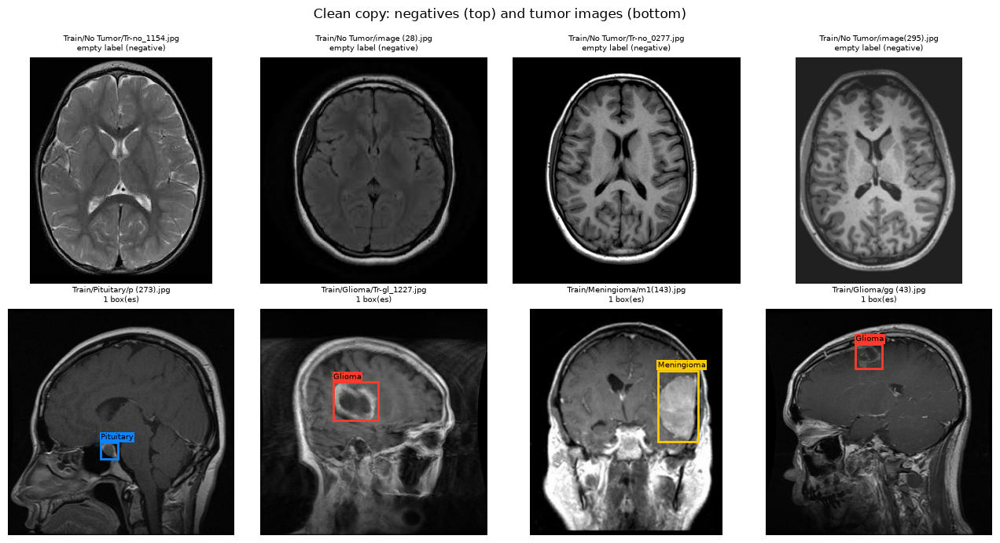

In [7]:
BOX_COLORS = {0: "#ff3b30", 1: "#ffcc00", 3: "#0a84ff"}


def show_ground_truth(ax, image_path, boxes):
    image = Image.open(image_path).convert("RGB")
    W, H = image.size
    ax.imshow(image)
    for c, xc, yc, w, h in boxes:
        x0, y0 = (xc - w / 2) * W, (yc - h / 2) * H
        ax.add_patch(Rectangle((x0, y0), w * W, h * H, fill=False, ec=BOX_COLORS[c], lw=2))
        ax.text(x0, y0 - 3, CLASS_NAMES[c], fontsize=7, va="bottom", bbox=dict(fc=BOX_COLORS[c], ec="none", pad=1))
    rel = Path(image_path).relative_to(CLEAN_ROOT)
    ax.set_title(f"{rel.parts[0]}/{rel.parts[1]}/{rel.name}\n" + (f"{len(boxes)} box(es)" if boxes else "empty label (negative)"), fontsize=7)
    ax.axis("off")


samples = (clean[clean["negative"]].sample(4, random_state=42).to_dict("records")
           + clean[~clean["negative"]].sample(4, random_state=42).to_dict("records"))
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for ax, row in zip(axes.flat, samples):
    show_ground_truth(ax, row["image"], row["boxes"])
fig.suptitle("Clean copy: negatives (top) and tumor images (bottom)")
plt.tight_layout()
plt.show()

## Step 3. Subset and train / validation / test split

The original Train/Val split is **not** reused: 474 images have an exact copy in the other split, so it would leak data. A new split is built from `data/clean_v1`.

**Grouping.** The dataset has no patient IDs, so images that probably come from the same patient or scan are grouped by two image-based rules and one filename rule:

| Link between two images | Rule |
|---|---|
| Exact duplicate | identical MD5 of the file |
| Near-duplicate | difference hash (dHash, 256 bits on a 17×16 grayscale thumbnail) differs in **≤ 28 bits** |
| Same series (adjacent slices) | consecutive file numbers in the same folder and name prefix, e.g. `p (33)` and `p (34)`, **and** dHash distance **≤ 48** |

Groups are the connected components of this graph, so a chain of links puts all its images in one group. The thresholds were chosen by inspecting pairs visually: up to about 33 bits the pairs were the same image or an adjacent slice of the same scan, while at 34–40 bits unrelated patients from different classes already appear. Pairs with consecutive numbers at 41–48 bits were adjacent slices of one scan. Because there are no patient IDs, this is an approximation: two scans of one patient that look different can still end up in different splits.

**Subset rules.**

1. A group is excluded if any of its images is flagged as ambiguous in Step 1 (more than one class in the label, no box of the folder class, or duplicate copies annotated differently) or if its images come from more than one class folder. These images stay in `data/clean_v1` for later review.
2. Exact duplicates are reduced to one copy.
3. Groups are drawn at random per class (seed 42) until the class reaches its target: 350 Glioma, 350 Meningioma, 350 Pituitary and 300 No Tumor images, **1,350 in total**. At most 3 images are taken from one group so that one scan does not dominate.
4. Whole groups are assigned to train / val / test with a 70 / 15 / 15 target per class: each group, in random order, goes to the split that is furthest below its target.
5. Classes are remapped for three tumor classes: Glioma 0, Meningioma 1, Pituitary 3 → 2. No Tumor images keep empty label files (background images).

The result is written to `data/subset_v1` in the Ultralytics layout (`images/<split>`, `labels/<split>`, `data.yaml`) and packed into `data/subset_v1.zip` for Colab. Every image's source and group are saved to `reports/split_v1_manifest.csv`, and the method, parameters, seed and counts to `reports/split_v1_config.json`.

In [8]:
import json
import re
from datetime import datetime, timezone

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

SEED = 42
SUBSET_ROOT = Path("data/subset_v1")
NEAR_DUP_MAX_DIST = 28   # dHash bits (of 256) for near-duplicates
SEQ_MAX_DIST = 48        # looser limit for consecutive file numbers (adjacent slices)
MAX_PER_GROUP = 3
TARGET_IMAGES = {"Glioma": 350, "Meningioma": 350, "Pituitary": 350, "No Tumor": 300}
SPLIT_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}
NEW_CLASS_ID = {0: 0, 1: 1, 3: 2}   # Pituitary 3 -> 2; No Tumor images have no boxes
NEW_CLASS_NAMES = ["Glioma", "Meningioma", "Pituitary"]
FLAG_COLUMNS = ["multi_class", "folder_mismatch", "dup_label_conflict"]


def dhash_bits(path, size=16):
    # Difference hash: is each pixel brighter than its left neighbour on a (size+1) x size thumbnail?
    with Image.open(path) as im:
        a = np.asarray(im.convert("L").resize((size + 1, size), Image.LANCZOS), dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).ravel()


def name_parts(stem):
    # 'gg (342)' -> ('gg', 342), 'Tr-gl_0043' -> ('Tr-gl', 43); stems without a number get -1
    m = re.fullmatch(r"(.*?)[ _]?\(?(\d+)\)?", stem)
    return (m.group(1).strip(), int(m.group(2))) if m else (stem, -1)


pool = clean.rename(columns={"split": "orig_split"})
pool["rel"] = pool["image"].map(lambda p: Path(p).relative_to(CLEAN_ROOT).as_posix())
pool = (pool.merge(audit[["image", "md5", *FLAG_COLUMNS]].rename(columns={"image": "rel"}),
                   on="rel", how="left", validate="one_to_one")
            .sort_values("rel", ignore_index=True))
assert pool["md5"].notna().all()
pool[["prefix", "number"]] = pd.DataFrame(pool["rel"].map(lambda r: name_parts(Path(r).stem)).tolist(),
                                          columns=["prefix", "number"])

# Pairwise Hamming distances between dHashes
bits = np.stack([dhash_bits(p) for p in pool["image"]]).astype(np.float32)
ones = bits.sum(axis=1)
dist = np.rint(ones[:, None] + ones[None, :] - 2 * bits @ bits.T).astype(np.int16)

# Consecutive file numbers within the same folder and prefix
consecutive = np.zeros(dist.shape, dtype=bool)
for _, g in pool.groupby(["folder", "prefix"]):
    g = g.sort_values("number")
    idx, num = g.index.to_numpy(), g["number"].to_numpy()
    step = np.flatnonzero(np.diff(num) == 1)
    consecutive[idx[step], idx[step + 1]] = consecutive[idx[step + 1], idx[step]] = True

md5 = pool["md5"].to_numpy()
edges = (md5[:, None] == md5[None, :]) | (dist <= NEAR_DUP_MAX_DIST) | (consecutive & (dist <= SEQ_MAX_DIST))
n_groups, pool["group"] = connected_components(csr_matrix(edges), directed=False)

by_group = pool.groupby("group")
groups = pd.DataFrame({
    "size": by_group.size(),
    "n_folders": by_group["folder"].nunique(),
    "folder": by_group["folder"].first(),
    "flagged": by_group[FLAG_COLUMNS].any().any(axis=1),
})
groups["eligible"] = (groups["n_folders"] == 1) & ~groups["flagged"]
pool["eligible"] = pool["group"].map(groups["eligible"])

display(pd.Series({
    "Images in clean_v1": len(pool),
    "Groups": n_groups,
    "  - single-image groups": (groups["size"] == 1).sum(),
    "  - largest group (images)": groups["size"].max(),
    "Images with an exact duplicate": pool["md5"].duplicated(keep=False).sum(),
    "Groups spanning several class folders": (groups["n_folders"] > 1).sum(),
    "Groups with a flagged (ambiguous) image": groups["flagged"].sum(),
    "Images in eligible groups": pool["eligible"].sum(),
    "Unique eligible images (one copy per MD5)": pool.loc[pool["eligible"], "md5"].nunique(),
}, name="count").to_frame())
display(pool[pool["eligible"]].drop_duplicates("md5").groupby("folder")
        .agg(images=("rel", "size"), groups=("group", "nunique")))

,count
Images in clean_v1,5248
Groups,2141
- single-image groups,1079
- largest group (images),36
Images with an exact duplicate,2564
Groups spanning several class folders,1
Groups with a flagged (ambiguous) image,201
Images in eligible groups,4454
Unique eligible images (one copy per MD5),3343


,images,groups
folder,,
Glioma,896,572
Meningioma,938,691
No Tumor,601,312
Pituitary,908,364


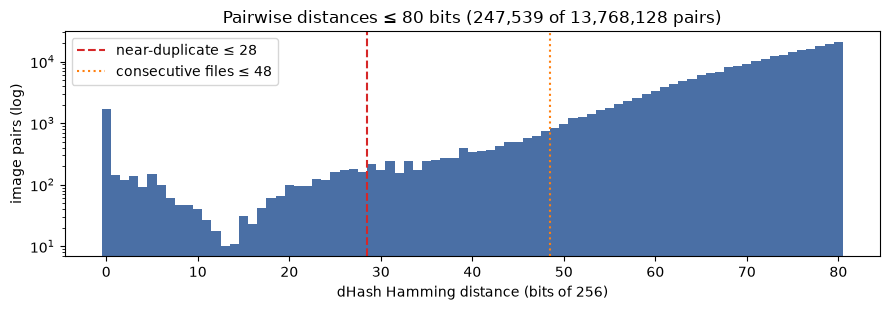

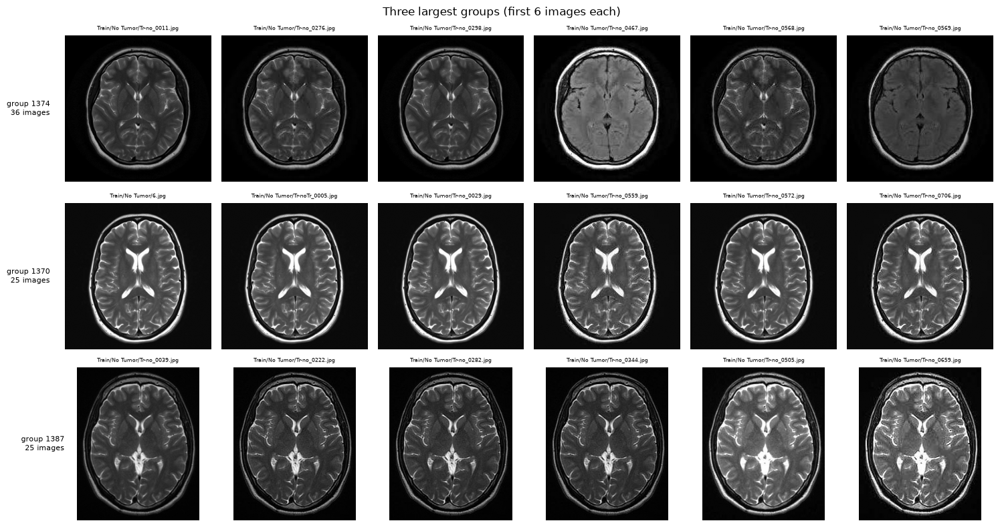

In [9]:
# Distribution of dHash distances: exact copies at 0, a dip near 13-14 bits, unrelated images mostly > 60
d = dist[np.triu_indices_from(dist, k=1)]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(d[d <= 80], bins=np.arange(82) - 0.5, color="#4a6fa5")
ax.axvline(NEAR_DUP_MAX_DIST + 0.5, color="#d62728", ls="--", label=f"near-duplicate ≤ {NEAR_DUP_MAX_DIST}")
ax.axvline(SEQ_MAX_DIST + 0.5, color="#ff7f0e", ls=":", label=f"consecutive files ≤ {SEQ_MAX_DIST}")
ax.set_yscale("log")
ax.set_xlabel("dHash Hamming distance (bits of 256)")
ax.set_ylabel("image pairs (log)")
ax.set_title(f"Pairwise distances ≤ 80 bits ({(d <= 80).sum():,} of {len(d):,} pairs)")
ax.legend()
plt.tight_layout()
plt.show()

# The largest groups and two examples of chained near-duplicates
largest = groups.sort_values("size", ascending=False).head(3).index
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for row_axes, gid in zip(axes, largest):
    members = pool[pool["group"] == gid]
    for ax, rec in zip(row_axes, members.head(6).itertuples()):
        ax.imshow(Image.open(rec.image).convert("L"), cmap="gray")
        ax.set_title(rec.rel.replace("/images/", "/"), fontsize=6)
    for ax in row_axes:
        ax.axis("off")
    row_axes[0].text(-0.1, 0.5, f"group {gid}\n{len(members)} images", transform=row_axes[0].transAxes,
                     ha="right", va="center", fontsize=8)
fig.suptitle("Three largest groups (first 6 images each)")
plt.tight_layout()
plt.show()

In [10]:
rng = np.random.default_rng(SEED)
candidates = pool[pool["eligible"]].drop_duplicates("md5")   # one copy of each exact duplicate

chosen = []
for folder, target in TARGET_IMAGES.items():
    class_groups = rng.permutation(np.sort(candidates.loc[candidates["folder"] == folder, "group"].unique()))
    split_counts = dict.fromkeys(SPLIT_FRACTIONS, 0)
    taken = 0
    for gid in class_groups:
        if taken >= target:
            break
        members = candidates[candidates["group"] == gid]
        k = min(MAX_PER_GROUP, len(members), target - taken)
        picked = members.iloc[np.sort(rng.choice(len(members), size=k, replace=False))]
        # the split that is furthest below its target share gets the whole group
        split = max(SPLIT_FRACTIONS, key=lambda s: SPLIT_FRACTIONS[s] * target - split_counts[s])
        split_counts[split] += k
        taken += k
        chosen.append(picked.assign(split=split))
    assert taken == target, f"{folder}: only {taken} images available"

subset = pd.concat(chosen, ignore_index=True)
folder_code = {"Glioma": "gl", "Meningioma": "me", "No Tumor": "no", "Pituitary": "pi"}
subset["file"] = [
    # e.g. 'Val/No Tumor/images/image (55).jpg' -> 'no_image_55_3fa2c1.jpg'; the MD5 prefix keeps names such as
    # 'image (55)' and 'image(55)' apart after cleaning. The original path is kept in the manifest.
    f"{folder_code[f]}_{re.sub(r'[^A-Za-z0-9]+', '_', Path(r).stem).strip('_')}_{m[:6]}{Path(r).suffix.lower()}"
    for f, r, m in zip(subset["folder"], subset["rel"], subset["md5"])
]
subset["new_boxes"] = subset["boxes"].map(lambda bs: [(NEW_CLASS_ID[c], xc, yc, w, h) for c, xc, yc, w, h in bs])

# Checks: no leakage between splits, every class in every split, unique file names
pos = subset.merge(pool.reset_index()[["rel", "index"]], on="rel")["index"].to_numpy()
cross = subset["split"].to_numpy()[:, None] != subset["split"].to_numpy()[None, :]
min_cross = dist[np.ix_(pos, pos)][cross].min()
assert subset.groupby("group")["split"].nunique().max() == 1, "a group is split across sets"
assert subset["md5"].is_unique, "exact duplicate inside the subset"
assert min_cross > NEAR_DUP_MAX_DIST, f"near-duplicate across splits ({min_cross} bits)"
assert subset["file"].is_unique
assert (subset.groupby("split")["folder"].nunique() == len(TARGET_IMAGES)).all()
print(f"Subset: {len(subset)} images from {subset['group'].nunique()} groups; "
      f"smallest dHash distance between images of different splits: {min_cross} bits. All checks passed.")

Subset: 1350 images from 904 groups; smallest dHash distance between images of different splits: 32 bits. All checks passed.


In [11]:
assert SUBSET_ROOT.resolve() not in (RAW_ROOT.resolve(), CLEAN_ROOT.resolve())
if SUBSET_ROOT.exists():
    shutil.rmtree(SUBSET_ROOT)   # always rebuilt from data/clean_v1
for split in SPLIT_FRACTIONS:
    (SUBSET_ROOT / "images" / split).mkdir(parents=True)
    (SUBSET_ROOT / "labels" / split).mkdir(parents=True)
for rec in subset.itertuples():
    shutil.copy2(rec.image, SUBSET_ROOT / "images" / rec.split / rec.file)
    (SUBSET_ROOT / "labels" / rec.split / f"{Path(rec.file).stem}.txt").write_text(
        "".join(f"{c} {xc} {yc} {w} {h}\n" for c, xc, yc, w, h in rec.new_boxes))

(SUBSET_ROOT / "data.yaml").write_text(
    "# Brain tumor detection subset v1 (see split_config.json).\n"
    "# 'path' is replaced with the absolute dataset folder by the training notebook.\n"
    "path: .\ntrain: images/train\nval: images/val\ntest: images/test\n"
    "names:\n" + "".join(f"  {i}: {n}\n" for i, n in enumerate(NEW_CLASS_NAMES)))

# Images and objects per split
split_order = list(SPLIT_FRACTIONS)
images_table = pd.crosstab(subset["folder"], subset["split"], margins=True, margins_name="Total")
images_table = images_table[split_order + ["Total"]]
objects = subset.explode("new_boxes", ignore_index=True).dropna(subset=["new_boxes"])
objects_table = pd.crosstab(objects["new_boxes"].map(lambda b: NEW_CLASS_NAMES[b[0]]), objects["split"],
                            rownames=["class"], margins=True, margins_name="Total")[split_order + ["Total"]]
print("Images per split (folder = image-level class; No Tumor images are background):")
display(images_table)
print("Objects (boxes) per split:")
display(objects_table)

split_manifest = (subset.assign(n_boxes_new=subset["new_boxes"].map(len),
                                classes_new=subset["new_boxes"].map(lambda bs: " ".join(str(c) for c in sorted({b[0] for b in bs}))))
                        .rename(columns={"rel": "source_image"})
                        [["split", "file", "source_image", "orig_split", "folder", "group", "md5", "n_boxes_new", "classes_new"]]
                        .sort_values(["split", "file"]))
split_manifest.to_csv(REPORT_DIR / "split_v1_manifest.csv", index=False)

split_config = {
    "dataset_version": "subset_v1",
    "created_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "source": "data/clean_v1 (Step 2 of notebook.ipynb, built from the Kaggle archive)",
    "random_seed": SEED,
    "rng": "numpy.random.default_rng(seed)",
    "method": ("Group images by exact MD5, dHash near-duplicates and consecutive file numbers; drop groups with "
               "ambiguous annotations or several class folders; keep one copy per MD5; sample whole groups per class "
               "(max images per group) to the target size; assign each group to the split furthest below its target share."),
    "dhash": {"bits": 256, "thumbnail": "17x16 grayscale, LANCZOS", "near_duplicate_max_distance": NEAR_DUP_MAX_DIST,
              "consecutive_files_max_distance": SEQ_MAX_DIST},
    "max_images_per_group": MAX_PER_GROUP,
    "target_images_per_class": TARGET_IMAGES,
    "split_fractions": SPLIT_FRACTIONS,
    "class_names": NEW_CLASS_NAMES,
    "class_remap_from_original": {"0 Glioma": 0, "1 Meningioma": 1, "3 Pituitary": 2, "2 No Tumor": "no boxes (background)"},
    "images_per_split": subset["split"].value_counts().reindex(split_order).to_dict(),
    "images_per_split_and_folder": {s: subset[subset["split"] == s]["folder"].value_counts().sort_index().to_dict() for s in split_order},
    "objects_per_split_and_class": {s: objects[objects["split"] == s]["new_boxes"].map(lambda b: NEW_CLASS_NAMES[b[0]]).value_counts().sort_index().to_dict() for s in split_order},
    "groups_per_split": subset.groupby("split")["group"].nunique().reindex(split_order).to_dict(),
    "min_dhash_distance_between_splits": int(min_cross),
}
(REPORT_DIR / "split_v1_config.json").write_text(json.dumps(split_config, indent=2, default=int))
shutil.copy2(REPORT_DIR / "split_v1_manifest.csv", SUBSET_ROOT / "split_manifest.csv")
shutil.copy2(REPORT_DIR / "split_v1_config.json", SUBSET_ROOT / "split_config.json")

archive = Path(shutil.make_archive(str(SUBSET_ROOT), "zip", root_dir=SUBSET_ROOT.parent, base_dir=SUBSET_ROOT.name))
archive = archive.relative_to(Path.cwd())
size_mb = archive.stat().st_size / 2**20
print(f"Saved {SUBSET_ROOT}/, {archive} ({size_mb:.1f} MB), "
      f"{REPORT_DIR / 'split_v1_manifest.csv'} and {REPORT_DIR / 'split_v1_config.json'}")

Images per split (folder = image-level class; No Tumor images are background):


split,train,val,test,Total
folder,,,,
Glioma,245,53,52,350
Meningioma,245,52,53,350
No Tumor,210,45,45,300
Pituitary,245,52,53,350
Total,945,202,203,1350


Objects (boxes) per split:


split,train,val,test,Total
class,,,,
Glioma,283,58,59,400
Meningioma,251,52,53,356
Pituitary,259,57,55,371
Total,793,167,167,1127


Saved data/subset_v1/, data/subset_v1.zip (32.7 MB), reports/split_v1_manifest.csv and reports/split_v1_config.json


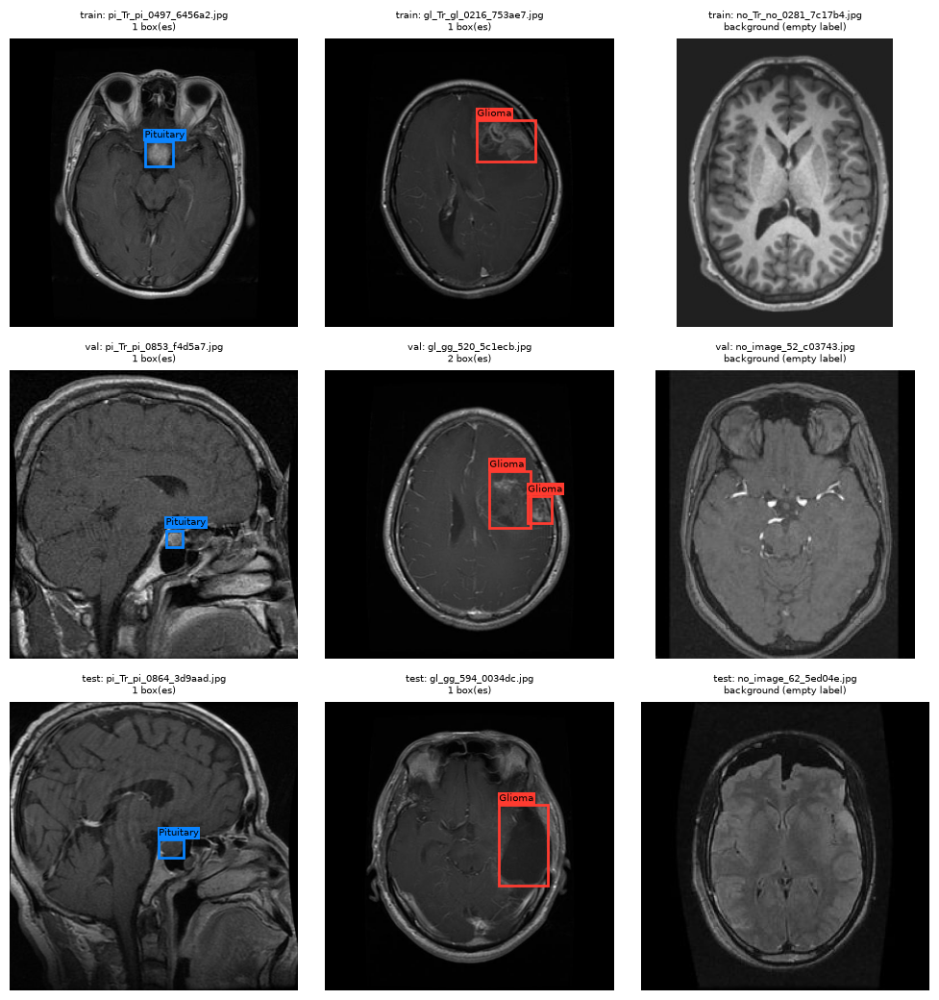

In [12]:
# Ground truth in the final subset: three images per split
NEW_COLORS = ["#ff3b30", "#ffcc00", "#0a84ff"]
fig, axes = plt.subplots(3, 3, figsize=(10, 10.5))
for row_axes, split in zip(axes, SPLIT_FRACTIONS):
    part = split_manifest[split_manifest["split"] == split]
    examples = pd.concat([part[part["n_boxes_new"] > 0].sample(2, random_state=SEED),
                          part[part["n_boxes_new"] == 0].sample(1, random_state=SEED)])
    for ax, rec in zip(row_axes, examples.itertuples()):
        image = Image.open(SUBSET_ROOT / "images" / split / rec.file).convert("RGB")
        W, H = image.size
        ax.imshow(image)
        label = (SUBSET_ROOT / "labels" / split / f"{Path(rec.file).stem}.txt").read_text().split("\n")
        for line in filter(None, label):
            c, xc, yc, w, h = int(line.split()[0]), *map(float, line.split()[1:])
            x0, y0 = (xc - w / 2) * W, (yc - h / 2) * H
            ax.add_patch(Rectangle((x0, y0), w * W, h * H, fill=False, ec=NEW_COLORS[c], lw=2))
            ax.text(x0, y0 - 3, NEW_CLASS_NAMES[c], fontsize=7, va="bottom", bbox=dict(fc=NEW_COLORS[c], ec="none", pad=1))
        ax.set_title(f"{split}: {rec.file}\n" + (f"{rec.n_boxes_new} box(es)" if rec.n_boxes_new else "background (empty label)"), fontsize=7)
        ax.axis("off")
plt.tight_layout()
Path("viz").mkdir(exist_ok=True)
fig.savefig("viz/split_v1_examples.png", dpi=110)
plt.show()

## Step 4. Training and controlled experiments

Run [train_colab.ipynb](train_colab.ipynb) on a Colab T4 to train the baseline and both experiments. The notebook also supports evaluation of the saved checkpoint and generates test predictions.

YOLO11n fit the Colab T4 budget and was fine-tuned from COCO weights. The baseline uses SGD, 50 epochs, an image size of 512, and seed 42. Both experiments start from the same `yolo11n.pt` and use the same split.

- **100 epochs.** The rationale for the longer schedule was that extra training could improve localization. This rationale was documented after the historical run. The epoch budget also controls the learning-rate schedule and when mosaic is disabled.
- **Lower learning rate.** The hypothesis was that reducing `lr0` from 0.01 to 0.005 would improve validation mAP by adapting the pretrained weights more gradually. The comparison uses 50 epochs for both runs.

The historical results below were recorded using the same validation settings. The lower learning rate yielded the highest mAP@0.50. The 100-epoch run had the highest mAP averaged over IoU thresholds from 0.50 through 0.95, the criterion used to select the final checkpoint. It took 19.98 minutes versus 10.70 for baseline. The precision and recall values are measured at the confidence giving the highest mean F1 for each model.

| Run | Epochs | Initial LR | Precision | Recall | mAP@0.50 | mAP@0.50–0.95 | Train min |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Baseline | 50 | 0.010 | 0.870 | 0.901 | 0.934 | 0.692 | 10.70 |
| Longer schedule | 100 | 0.010 | 0.907 | 0.889 | 0.936 | **0.707** | 19.98 |
| Lower LR | 50 | 0.005 | 0.917 | 0.910 | **0.949** | 0.697 | 11.23 |

The lower learning rate result supports the hypothesis within this run. Its gain at IoU 0.50 (+0.015) was larger than its gain across IoU 0.50–0.95 (+0.005). For Glioma, mAP@0.50 improved from 0.933 to 0.945 and mAP@0.50–0.95 fell from 0.685 to 0.664. The overall gain varied by class and overlap threshold. The longer run traded additional training time and lower recall at its selected operating point for higher mAP@0.50–0.95. These comparisons use one seed per setting.

## Step 5. Final evaluation on the test split

Compare all three recorded runs on validation mAP@0.50:0.95 and evaluate the selected `best.pt` on the held-out test set. The 100-epoch run wins on this criterion (0.707 versus 0.697 for the lower learning rate and 0.692 for baseline). The reported test evaluation uses the 100-epoch checkpoint. The later learning-rate comparison uses validation only.

To run the tests below, keep the project run folders in `runs/`, prepare the subset using Step 3, and install `ultralytics==8.4.190`.

In [13]:
%pip install -q ultralytics==8.4.190


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import ultralytics
from ultralytics import YOLO
from ultralytics.utils.metrics import smooth

RUNS_DIR = Path("runs")
run_names = ["baseline_yolo11n_512", "exp_epochs100", "exp_lr00.005"]
runs = {name: json.loads((RUNS_DIR / name / "run_info.json").read_text()) for name in run_names}
comparison = pd.DataFrame({
    name: {"epochs": info["settings"]["epochs"], "lr0": info["settings"]["lr0"], "best epoch": info["best_epoch"],
           "train time, min": info["training_time_minutes"], **info["validation_metrics_best"]}
    for name, info in runs.items()}).T
display(comparison.rename(columns={m: f"val {m}" for m in ["precision", "recall", "mAP50", "mAP50-95"]}).round(3))

FINAL_RUN = comparison["mAP50-95"].astype(float).idxmax()   # chosen on validation only
BEST_PT = RUNS_DIR / FINAL_RUN / "weights" / "best.pt"
TEST_DIR = RUNS_DIR / FINAL_RUN / "test_eval"
TEST_DIR.mkdir(parents=True, exist_ok=True)
print(f"Final run: {FINAL_RUN}, checkpoint {BEST_PT}")

### Test metrics

Standard Ultralytics evaluation, the same settings as for validation in `train_colab.ipynb`:

- `conf=0.001`: almost every prediction is kept, so the whole precision–recall curve is available for mAP;
- `iou=0.7`: IoU threshold of non-maximum suppression (overlapping predictions above it are merged into one);
- a prediction is correct if its class is right and its IoU with a ground-truth box is at least 0.5 (mAP@0.50); mAP@0.50:0.95 averages over IoU 0.50, 0.55, …, 0.95;
- Ultralytics reports precision and recall at one confidence threshold, the one that maximises the mean F1 score over classes; it is printed below.

In [15]:
TEST_SETTINGS = {"split": "test", "imgsz": 512, "batch": 16, "conf": 0.001, "iou": 0.7}

# Ultralytics needs an absolute dataset path
data_yaml = TEST_DIR / "data_test.yaml"
data_yaml.write_text((SUBSET_ROOT / "data.yaml").read_text().replace("path: .", f"path: {SUBSET_ROOT.resolve()}"))
final_model = YOLO(BEST_PT)
test = final_model.val(data=str(data_yaml), plots=True, project=str(TEST_DIR.resolve()), name="val_test",
                       exist_ok=True, verbose=False, **TEST_SETTINGS)
data_yaml.unlink()

box = test.box
PR_CONF = float(box.px[smooth(box.f1_curve.mean(0), 0.1).argmax()])   # where Ultralytics reads P and R
test_per_class = pd.DataFrame(
    [dict(zip(["precision", "recall", "mAP50", "mAP50-95"], box.class_result(i)), cls=test.names[int(c)])
     for i, c in enumerate(box.ap_class_index)]).set_index("cls")
test_per_class.loc["all"] = [box.mp, box.mr, box.map50, box.map]
test_per_class.to_csv(TEST_DIR / "per_class_metrics.csv", float_format="%.4f")
print(f"Settings: {TEST_SETTINGS}; precision and recall at conf = {PR_CONF:.3f}")
display(test_per_class.round(3))

Ultralytics 8.4.190 🚀 Python-3.14.2 torch-2.13.0 CPU (Apple M4)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 137.6±25.5 MB/s, size: 16.6 KB)
val: Scanning /Users/kana/Desktop/without network/bonus_task/data/subset_v1/labels/test... 203 images, 45 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 203/203 6.5Kit/s 0.0s
val: New cache created: /Users/kana/Desktop/without network/bonus_task/data/subset_v1/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 3.3it/s 4.0s0.3s
                   all        203        167       0.94      0.881      0.946      0.729
Speed: 0.2ms preprocess, 17.9ms inference, 0.0ms loss, 0.1ms postprocess per image
Results saved to /Users/kana/Desktop/without network/bonus_task/runs/exp_epochs100/test_eval/val_test
Settings: {'split': 'test', 'imgsz': 512, 'batch': 16, 'conf': 0.001, 'iou': 0.7}; precision

,precision,recall,mAP50,mAP50-95
cls,,,,
Glioma,0.910,0.678,0.859,0.611
Meningioma,0.981,1.000,0.995,0.880
Pituitary,0.929,0.964,0.983,0.696
all,0.940,0.881,0.946,0.729


### Precision and recall at the deployment threshold

The prediction images use `conf=0.25`, the Ultralytics default for `predict`. At this threshold every test box is counted: a prediction is a true positive if it has the right class and IoU ≥ 0.5 with a ground-truth box that is not matched yet (predictions are matched from the highest confidence down); other predictions are false positives, unmatched ground-truth boxes are false negatives (missed tumours).

In [16]:
PRED_CONF, MATCH_IOU = 0.25, 0.5


def box_iou(a, b):
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - ix * iy
    return ix * iy / union if union > 0 else 0.0


def read_gt(image_path, W, H):
    label = SUBSET_ROOT / "labels" / "test" / f"{image_path.stem}.txt"
    gt = []
    for line in filter(None, label.read_text().splitlines()):
        c, xc, yc, w, h = int(line.split()[0]), *map(float, line.split()[1:])
        gt.append((c, [(xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H]))
    return gt


counts = pd.DataFrame(0, index=NEW_CLASS_NAMES, columns=["TP", "FP", "FN"])
test_rows, test_preds = [], {}
for image_path in sorted((SUBSET_ROOT / "images" / "test").iterdir()):
    image = Image.open(image_path)
    gt = read_gt(image_path, *image.size)
    r = final_model.predict(image_path, imgsz=TEST_SETTINGS["imgsz"], conf=PRED_CONF, iou=TEST_SETTINGS["iou"],
                            verbose=False)[0]
    preds = sorted(zip(r.boxes.cls.int().tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist()), key=lambda p: -p[1])
    used, tp, fp = set(), 0, 0
    for c, p, b in preds:
        hits = [(box_iou(b, g), j) for j, (gc, g) in enumerate(gt) if gc == c and j not in used]
        best_iou, j = max(hits, default=(0.0, None))
        if best_iou >= MATCH_IOU:
            used.add(j)
            counts.loc[NEW_CLASS_NAMES[c], "TP"] += 1
            tp += 1
        else:
            counts.loc[NEW_CLASS_NAMES[c], "FP"] += 1
            fp += 1
    for j, (gc, _) in enumerate(gt):
        if j not in used:
            counts.loc[NEW_CLASS_NAMES[gc], "FN"] += 1
    test_preds[image_path.name] = (gt, preds)
    test_rows.append({"file": image_path.name, "gt": " ".join(NEW_CLASS_NAMES[c] for c, _ in gt),
                      "pred": " ".join(f"{NEW_CLASS_NAMES[c]}:{p:.2f}" for c, p, _ in preds),
                      "TP": tp, "FP": fp, "FN": len(gt) - len(used),
                      # best IoU of each GT box with any prediction, whatever its class
                      "gt_best_iou": " ".join(f"{max((box_iou(g, b) for _, _, b in preds), default=0):.2f}"
                                              for _, g in gt)})

counts.loc["all"] = counts.sum()
counts["precision"] = counts["TP"] / (counts["TP"] + counts["FP"])
counts["recall"] = counts["TP"] / (counts["TP"] + counts["FN"])
test_images = pd.DataFrame(test_rows)
test_images.to_csv(TEST_DIR / "per_image_conf025.csv", index=False)
errors = test_images[(test_images["FP"] > 0) | (test_images["FN"] > 0)]
print(f"conf = {PRED_CONF}, NMS IoU = {TEST_SETTINGS['iou']}, match IoU = {MATCH_IOU}")
display(counts.round(3))
print(f"{len(errors)} of {len(test_images)} test images have at least one error:")
display(errors.sort_values(["FN", "FP"], ascending=False).reset_index(drop=True))

conf = 0.25, NMS IoU = 0.7, match IoU = 0.5


,TP,FP,FN,precision,recall
Glioma,47,12,12,0.797,0.797
Meningioma,53,2,0,0.964,1.000
Pituitary,55,11,0,0.833,1.000
all,155,25,12,0.861,0.928


25 of 203 test images have at least one error:


,file,gt,pred,TP,FP,FN,gt_best_iou
0,gl_gg_786_b23cdb.jpg,Glioma Glioma,,0,0,2,0.00 0.00
1,gl_gg_459_daa65c.jpg,Glioma,Glioma:0.89 Glioma:0.77 Glioma:0.58,0,3,1,0.45
2,gl_Tr_gl_0962_bee359.jpg,Glioma Glioma,Glioma:0.94 Glioma:0.53,1,1,1,0.95 0.00
3,gl_gg_386_192a1a.jpg,Glioma,Glioma:0.82,0,1,1,0.26
4,gl_gg_536_bcf142.jpg,Glioma,Glioma:0.71,0,1,1,0.47
5,gl_gg_592_536cd5.jpg,Glioma,Glioma:0.27,0,1,1,0.00
6,gl_gg_787_36a287.jpg,Glioma,Glioma:0.75,0,1,1,0.49
7,gl_Tr_gl_0060_110474.jpg,Glioma Glioma,Glioma:0.88,1,0,1,0.80 0.07
8,gl_Tr_gl_0170_7090c4.jpg,Glioma Glioma,Glioma:0.91,1,0,1,0.83 0.00
9,gl_gg_468_3cc58d.jpg,Glioma Glioma,Glioma:0.50,1,0,1,0.00 0.89


### Test images with predictions

Two random test images per source folder (seed 42), not hand-picked. Coloured boxes are predictions with class name and confidence (conf ≥ 0.25), dashed white boxes are ground truth.

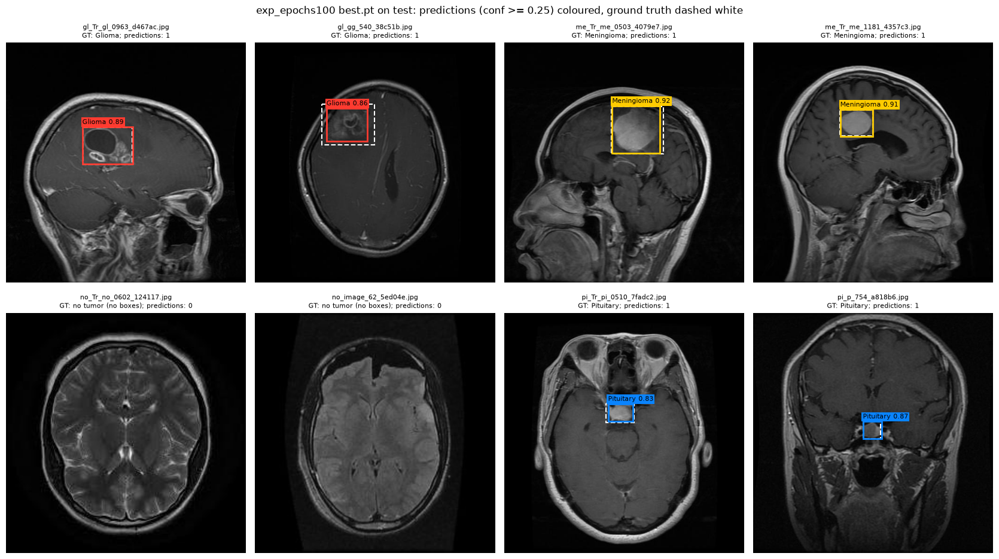

In [17]:
def draw_test_boxes(ax, file):
    gt, preds = test_preds[file]
    with Image.open(SUBSET_ROOT / "images" / "test" / file) as image:
        ax.imshow(image.convert("RGB"))
    for _, (x0, y0, x1, y1) in gt:
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="white", lw=1.5, ls="--"))
    for c, p, (x0, y0, x1, y1) in preds:
        color = NEW_COLORS[c]
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=color, lw=2))
        ax.text(x0, max(0, y0 - 3), f"{NEW_CLASS_NAMES[c]} {p:.2f}", fontsize=8, va="bottom",
                bbox=dict(fc=color, ec="none", pad=1.5))
    ax.set_axis_off()


examples = (split_manifest[split_manifest["split"] == "test"]
            .groupby("folder").sample(2, random_state=SEED).sort_values(["folder", "file"]))
fig, axes = plt.subplots(2, 4, figsize=(16.8, 9.8))
for ax, rec in zip(axes.flat, examples.itertuples()):
    draw_test_boxes(ax, rec.file)
    gt, preds = test_preds[rec.file]
    gt_text = ", ".join(NEW_CLASS_NAMES[c] for c, _ in gt) or "no tumor (no boxes)"
    ax.set_title(f"{rec.file}\nGT: {gt_text}; predictions: {len(preds)}", fontsize=8)
fig.suptitle(f"{FINAL_RUN} best.pt on test: predictions (conf >= {PRED_CONF}) coloured, ground truth dashed white")
plt.tight_layout()
fig.savefig(TEST_DIR / "test_predictions.png", dpi=110)
plt.show()

In [18]:
# Everything needed for the report
test_report = {
    "run": FINAL_RUN, "checkpoint": str(BEST_PT), "selected_by": "validation mAP@0.50:0.95",
    "n_images": len(test_images), "n_background_images": int((test_images["gt"] == "").sum()),
    "n_boxes": int(counts.loc["all", "TP"] + counts.loc["all", "FN"]),
    "versions": {"ultralytics": ultralytics.__version__, "torch": torch.__version__,
                 "device": str(final_model.device)},
    "ultralytics_val": {"settings": {**TEST_SETTINGS, "match_iou": 0.5,
                                     "precision_recall_at_conf": round(PR_CONF, 4)},
                        "metrics": test_per_class.round(4).to_dict(orient="index")},
    "fixed_threshold": {"settings": {"conf": PRED_CONF, "nms_iou": TEST_SETTINGS["iou"], "match_iou": MATCH_IOU},
                        "metrics": counts.round(4).to_dict(orient="index")},
    "prediction_examples": examples["file"].tolist(),
}
(TEST_DIR / "test_metrics.json").write_text(json.dumps(test_report, indent=2, default=int))
print("Saved:", *sorted(p.name for p in TEST_DIR.iterdir()), sep="\n  ")

Saved:
  per_class_metrics.csv
  per_image_conf025.csv
  test_metrics.json
  test_predictions.png
  val_test


### Test results

Final model: `exp_epochs100/weights/best.pt` (YOLO11n, 100 epochs, best epoch 99), chosen on validation mAP@0.50:0.95 (0.707 vs 0.697 for the lower learning rate and 0.692 for baseline). Test split: 203 images (45 No Tumor images without boxes), 167 tumour boxes.

| Evaluation | Confidence | NMS IoU | Match IoU | Precision | Recall | mAP@0.50 | mAP@0.50:0.95 |
|---|---|---:|---:|---:|---:|---:|---:|
| Ultralytics `val` (main result) | 0.001 for mAP; P and R at 0.758 (max mean F1) | 0.7 | 0.5 | **0.940** | **0.881** | **0.946** | 0.729 |
| Box counts at the deployment threshold | 0.25 | 0.7 | 0.5 | 0.861 | 0.928 | – | – |

Per class (Ultralytics `val`): Glioma P 0.910 / R 0.678 / mAP@0.50 0.859, Meningioma 0.981 / 1.000 / 0.995, Pituitary 0.929 / 0.964 / 0.983. Test mAP@0.50 is close to validation (0.946 vs 0.936).

At conf 0.25 the model makes 155 correct detections, 25 false detections and misses 12 boxes; 25 of 203 test images have at least one error. All 12 missed boxes are gliomas, and 2 of the 45 No Tumor images get a false Pituitary box. Glioma is the weakest class.

**What the metrics measure**

- **Precision**: the share of predicted boxes that are correct (right class, IoU ≥ 0.5 with a ground-truth box). Low precision means false alarms.
- **Recall**: the share of ground-truth tumours that the model finds. Low recall means missed tumours.
- **mAP@0.50**: for each class, the area under the precision–recall curve obtained by moving the confidence threshold from high to low, with IoU ≥ 0.5 counting as a hit; averaged over the three classes. It does not depend on a single threshold.
- **mAP@0.50:0.95**: the same, averaged over stricter IoU thresholds 0.50–0.95, so it also rewards tightly fitting boxes.

Saved in `runs/exp_epochs100/test_eval/`: `test_metrics.json` (settings, versions, all metrics), `per_class_metrics.csv`, `per_image_conf025.csv` (predictions and TP / FP / FN per image), `test_predictions.png`, and the Ultralytics curves and confusion matrices in `val_test/`.

### Three test failure cases

The examples use the selected 100-epoch checkpoint at confidence ≥ 0.25, NMS IoU 0.70, and match IoU 0.50. Dashed white boxes mark ground truth and solid colored boxes show predictions. Each observation is relative to the dataset annotations.

| Failure | Observation | Possible cause and follow-up |
| --- | --- | --- |
| Missed Glioma region · `gl_Tr_gl_0170_7090c4.jpg` | One of two annotated regions is detected at 0.91 confidence and 0.83 IoU. The smaller region has no overlapping prediction at this threshold. | The missed box covers about one-third of the area of the detected ground-truth box and its boundary looks less distinct in this slice. Check validation recall by box size and increase representation of reviewed small regions in training. |
| False Pituitary detection · `no_image_117_59e90c.jpg` | The source image is labeled No Tumor and has no ground-truth box. The model predicts Pituitary at 0.80 confidence. | The box covers a small bright area near the center of the sagittal image. The detector may be relying on local contrast that also occurs in background scans. Add reviewed hard negatives from the training pool and measure false positives on the validation background images. |
| Oversized Glioma box · `gl_gg_386_192a1a.jpg` | The predicted class is correct at 0.82 confidence, but the box covers almost four times the annotated area. Its IoU is 0.26, so evaluation counts one false positive and one missed box. | The predicted box includes adjacent structures with different intensities. The model may be learning a broader extent than the one defined by the labels. Audit the consistency of training boxes and measure localization at stricter IoU thresholds on validation. |

A practical next experiment is to review training boxes for small or ambiguously bounded Glioma regions, then compare recall by box size and mAP@0.50–0.95 on the same validation split.

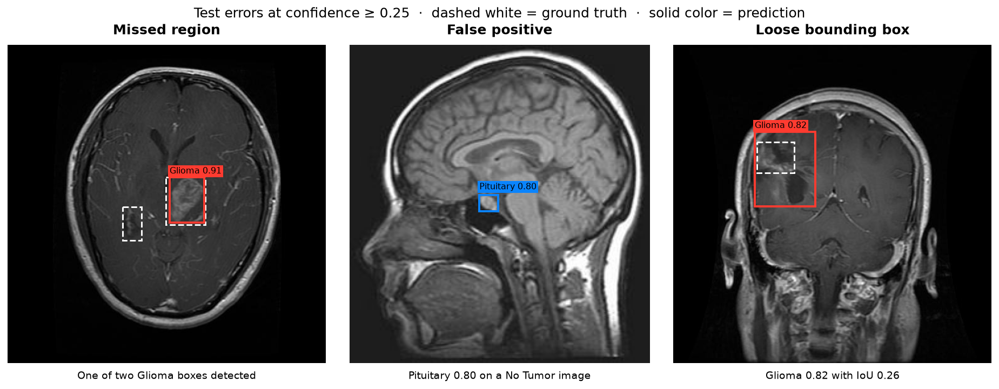

In [19]:
failure_cases = [
    ("Missed region", "gl_Tr_gl_0170_7090c4.jpg", "One of two Glioma boxes detected"),
    ("False positive", "no_image_117_59e90c.jpg", "Pituitary 0.80 on a No Tumor image"),
    ("Loose bounding box", "gl_gg_386_192a1a.jpg", "Glioma 0.82 with IoU 0.26"),
]

fig, axes = plt.subplots(1, len(failure_cases), figsize=(13.2, 5), layout="constrained")
for ax, (title, file, description) in zip(axes, failure_cases):
    draw_test_boxes(ax, file)
    ax.set_title(title, fontsize=13, fontweight="bold", pad=10)
    ax.text(0.5, -0.025, description, ha="center", va="top", transform=ax.transAxes, fontsize=10)
fig.suptitle("Test errors at confidence ≥ 0.25  ·  dashed white = ground truth  ·  solid color = prediction",
             fontsize=13)
fig.savefig(TEST_DIR / "failure_cases.png", dpi=140, bbox_inches="tight")
plt.show()